# Análisis exploratorio de datos

Exploración del conjunto de datos de precios de viviendas para entender su estructura y el comportamiento de la variable objetivo `SalePrice`.

## 1. Librerías

Importación de las librerías del ecosistema PyData utilizadas en el análisis.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import sklearn
import yaml

## 2. Carga de datos

Lectura de los conjuntos de entrenamiento y prueba. La ubicación de las fuentes se define en `DATA_DIR`, `TRAIN_FILE` y `TEST_FILE`; basta con modificar estas variables si los archivos cambian de ubicación.

In [3]:
# Rutas configurables: cambia DATA_DIR o los nombres de archivo si la fuente se mueve
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_FILE = "train.csv"
TEST_FILE = "test.csv"

train = pd.read_csv(DATA_DIR / TRAIN_FILE)
test = pd.read_csv(DATA_DIR / TEST_FILE)

print(f"train: {train.shape}, test: {test.shape}")

train: (1460, 81), test: (1459, 80)


## 3. Variable objetivo: `SalePrice`

Distribución del precio de venta mediante una gráfica de densidad, para identificar su forma, asimetría y posibles valores extremos. Se marcan la media (rojo) y la mediana (verde) como referencia de tendencia central.

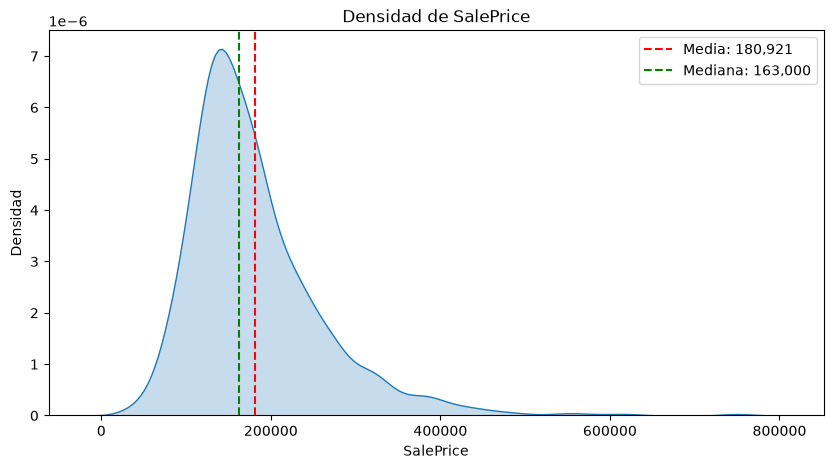

In [4]:
TARGET = "SalePrice"

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(data=train, x=TARGET, fill=True, ax=ax)

mean = train[TARGET].mean()
median = train[TARGET].median()
ax.axvline(mean, color="red", linestyle="--", label=f"Media: {mean:,.0f}")
ax.axvline(median, color="green", linestyle="--", label=f"Mediana: {median:,.0f}")

ax.set_title(f"Densidad de {TARGET}")
ax.set_xlabel(TARGET)
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

## 4. Clasificación de variables numéricas

Separación de las variables numéricas en discretas y continuas según su número de valores únicos: las variables con `DISCRETE_THRESHOLD` valores distintos o menos se consideran discretas. Se excluye `Id` por ser un identificador.

In [5]:
DISCRETE_THRESHOLD = 15

numeric_cols = train.select_dtypes(include="number").columns.drop([TARGET, "Id"])
n_unique = train[numeric_cols].nunique()

discretas = n_unique[n_unique <= DISCRETE_THRESHOLD].index.tolist()
continuas = n_unique[n_unique > DISCRETE_THRESHOLD].index.tolist()

correlations = train[numeric_cols].corrwith(train[TARGET])

print(f"Discretas ({len(discretas)}): {discretas}")
print(f"Continuas ({len(continuas)}): {continuas}")

Discretas (15): ['MSSubClass', 'OverallQual', 'OverallCond', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'PoolArea', 'MoSold', 'YrSold']
Continuas (21): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'MiscVal']


## 5. Variables continuas vs `SalePrice`

Diagramas de dispersión de cada variable continua frente a la variable objetivo para identificar relaciones lineales, no lineales y valores atípicos. El título de cada gráfica incluye el coeficiente de correlación de Pearson.

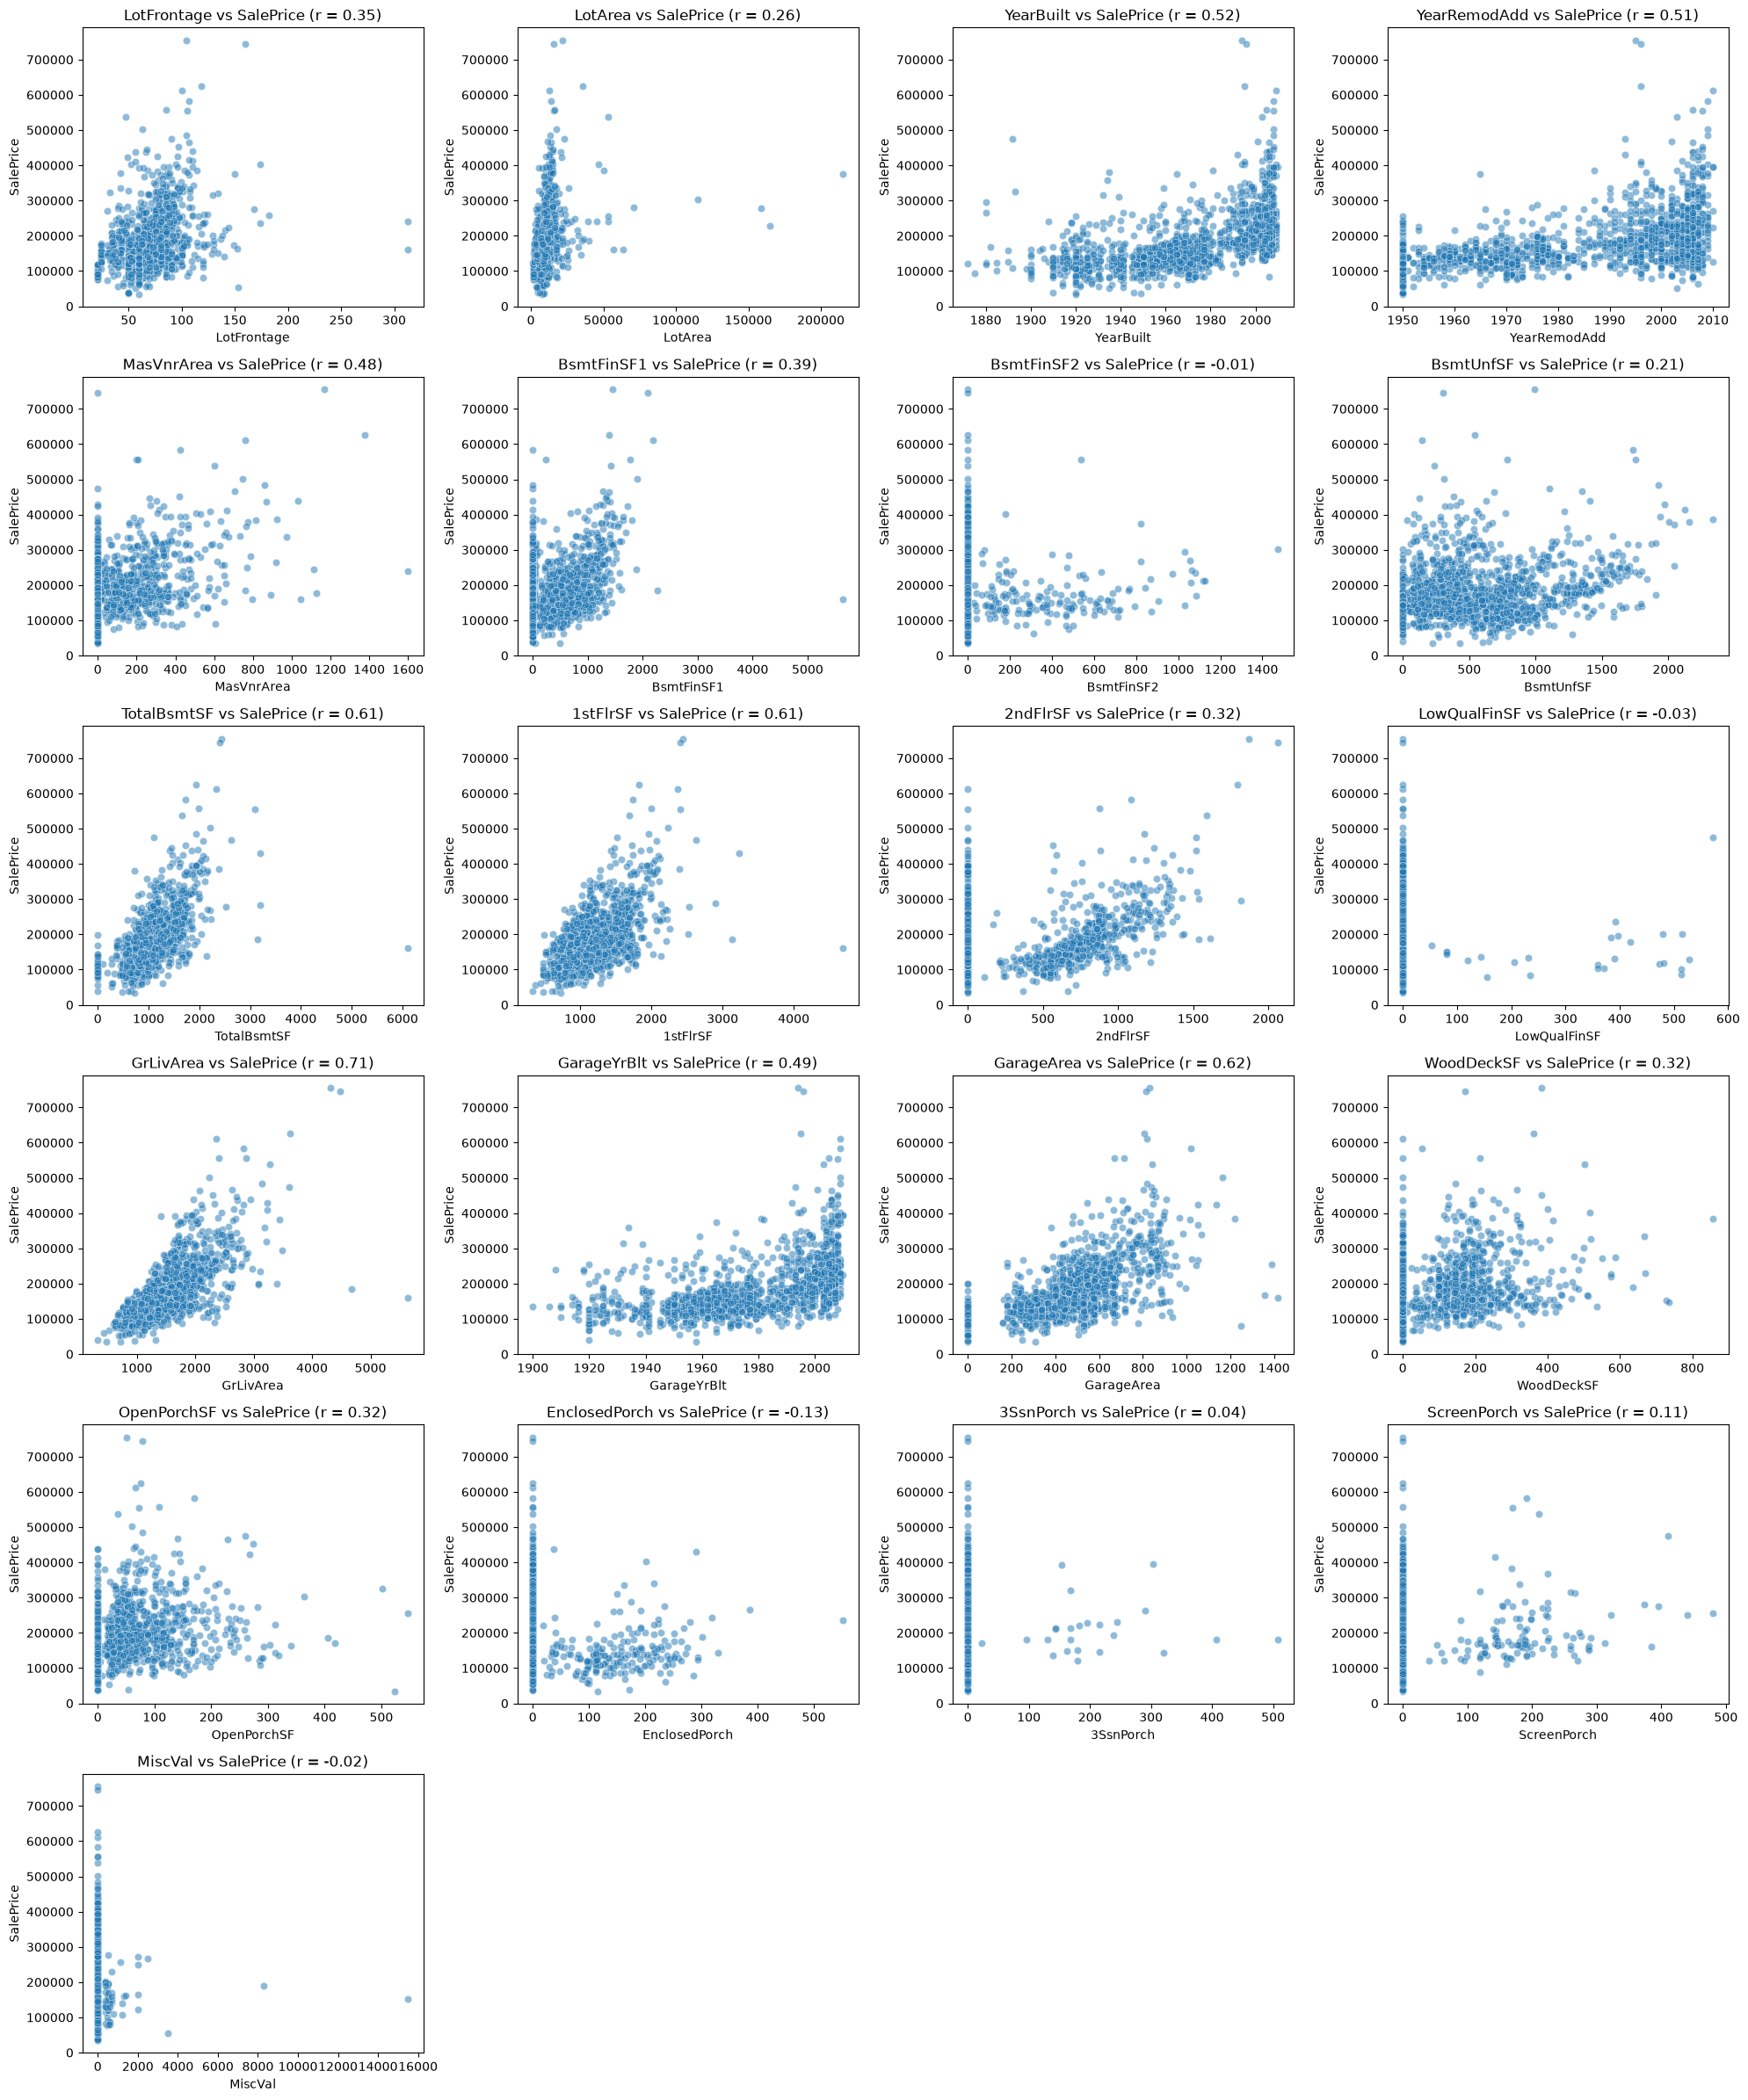

In [6]:
n_cols = 4
n_rows = int(np.ceil(len(continuas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, continuas):
    sns.scatterplot(data=train, x=col, y=TARGET, alpha=0.5, ax=ax)
    ax.set_title(f"{col} vs {TARGET} (r = {correlations[col]:.2f})")

for ax in axes[len(continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 6. Variables discretas vs `SalePrice`

Diagramas de caja de la variable objetivo para cada valor de las variables discretas, con las observaciones individuales superpuestas (`stripplot` con dispersión horizontal) para visualizar la cantidad de registros por categoría y su distribución.

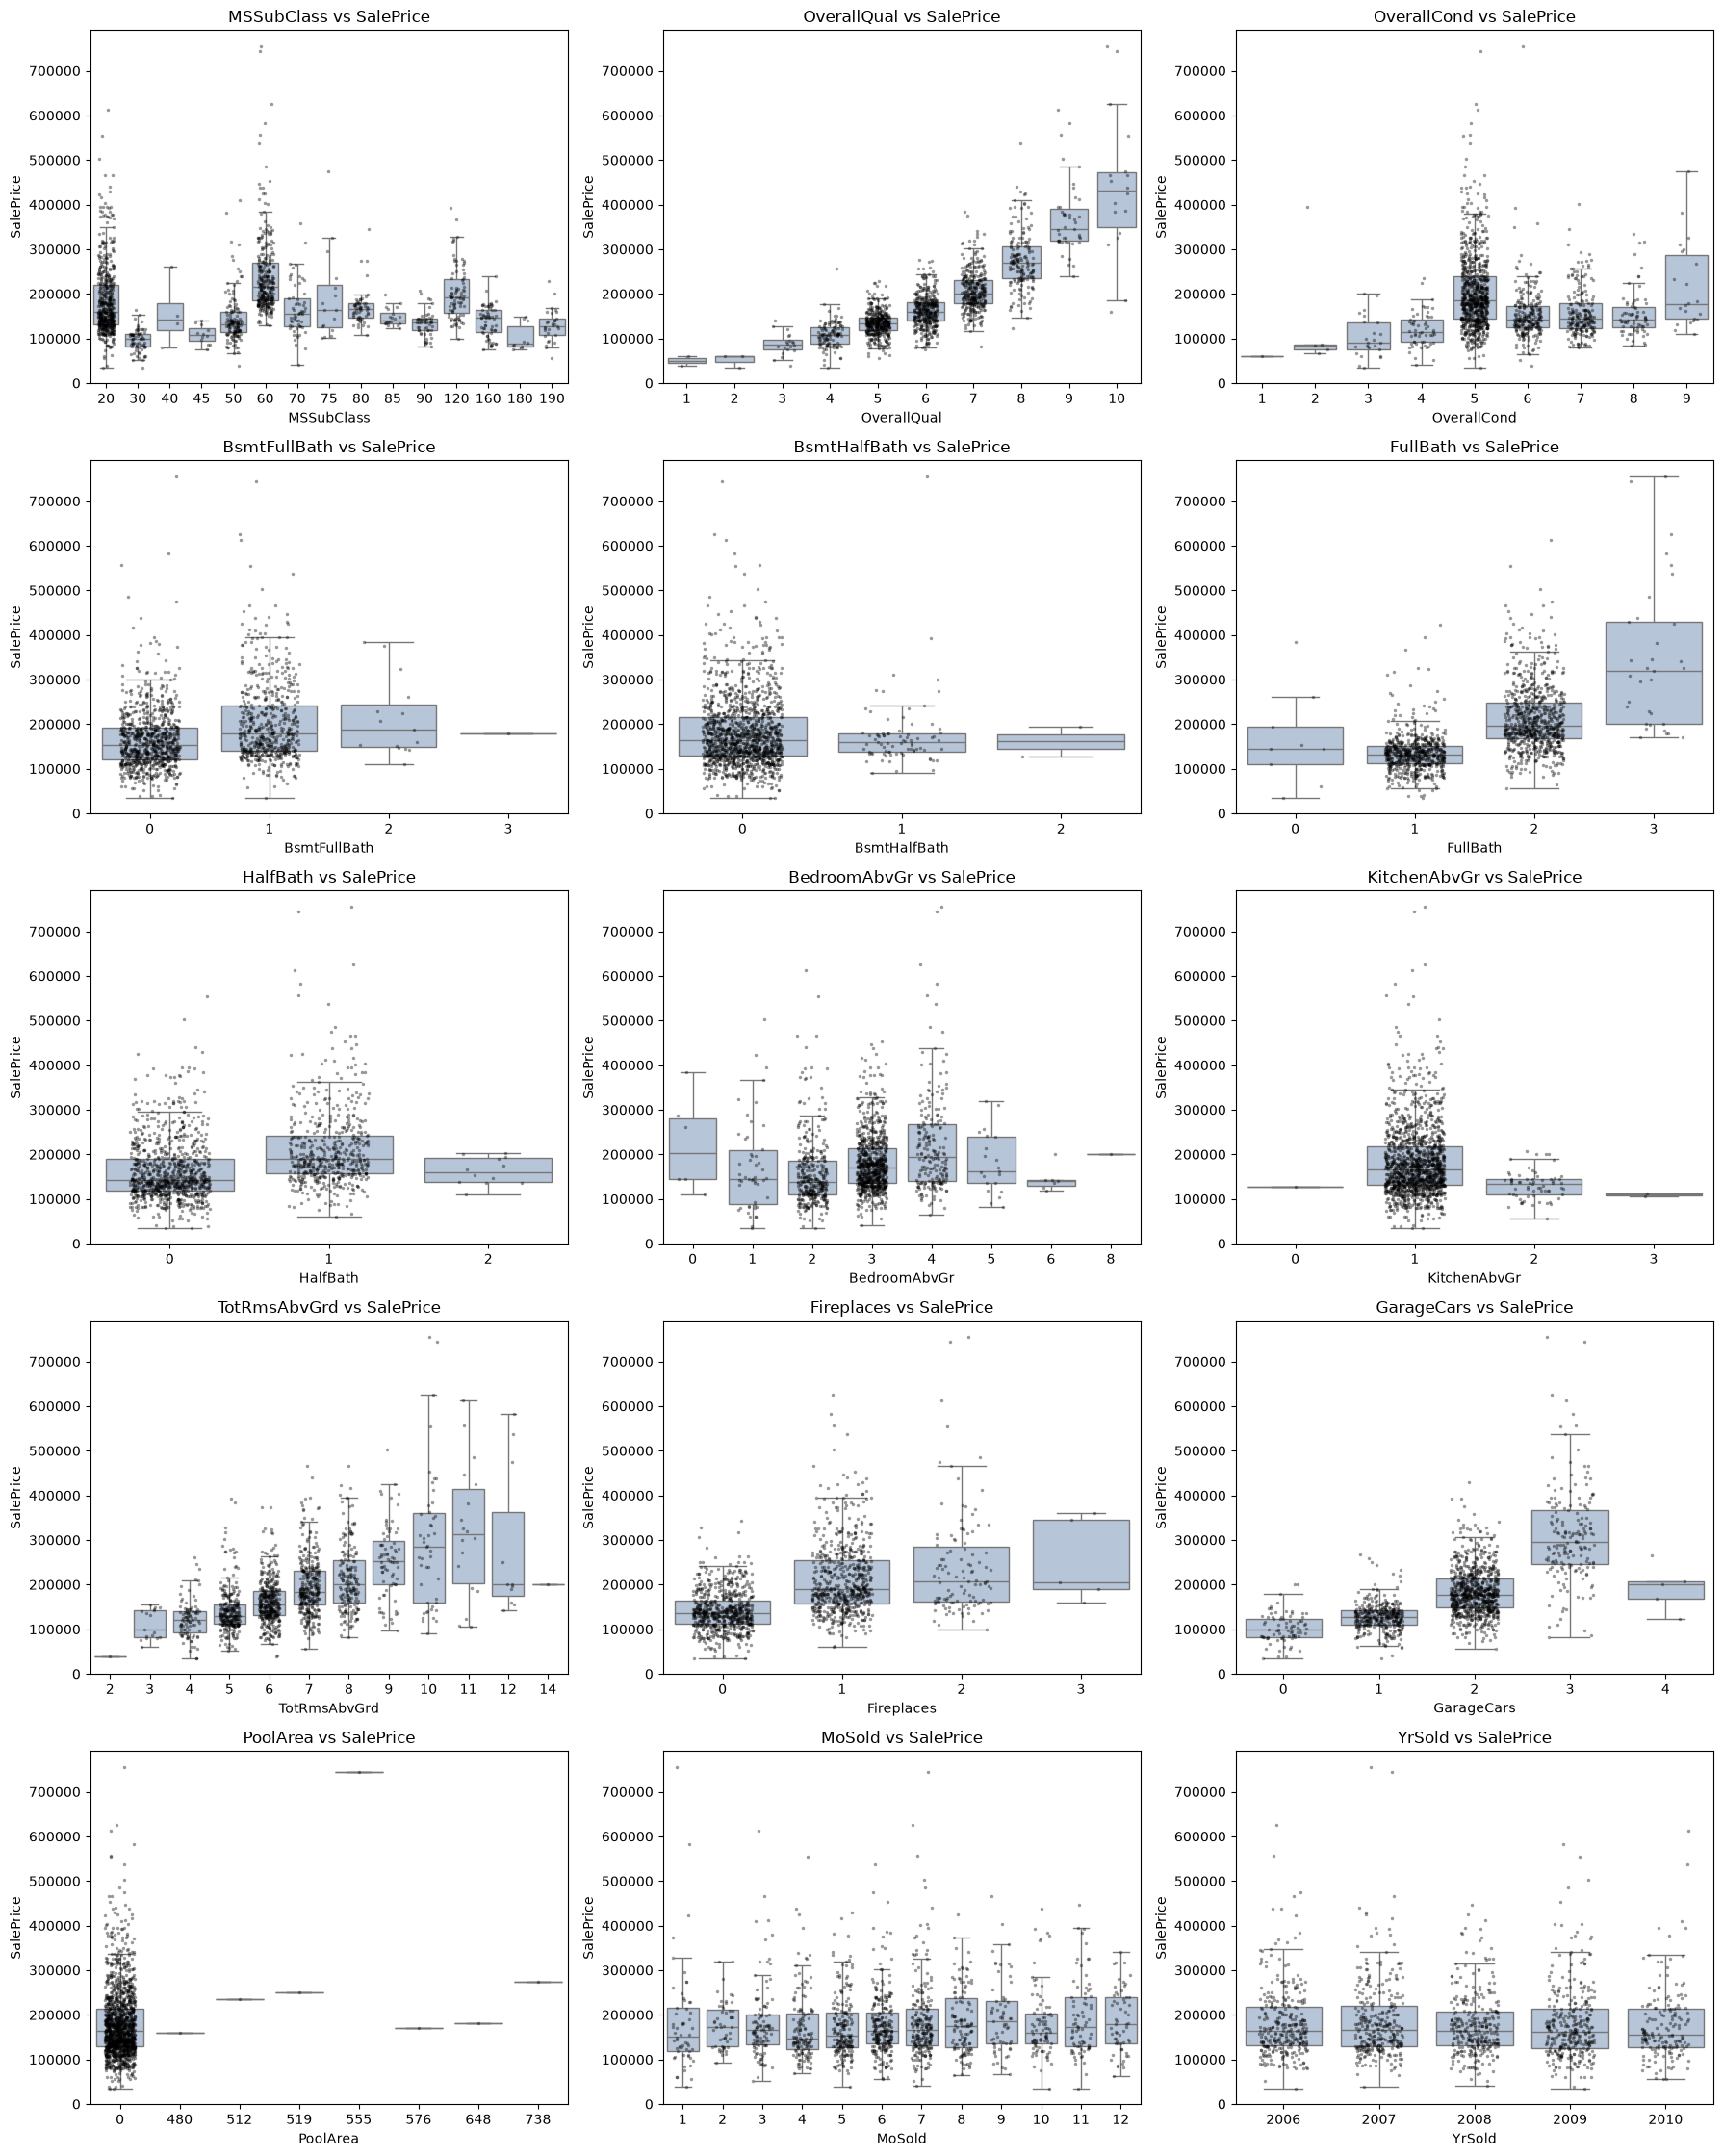

In [7]:
n_cols = 3
n_rows = int(np.ceil(len(discretas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, discretas):
    sns.boxplot(data=train, x=col, y=TARGET, showfliers=False, color="lightsteelblue", ax=ax)
    sns.stripplot(data=train, x=col, y=TARGET, jitter=0.25, size=2.5, alpha=0.4, color="black", ax=ax)
    ax.set_title(f"{col} vs {TARGET}")

for ax in axes[len(discretas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 7. Ranking de correlaciones con `SalePrice`

Coeficientes de correlación de Pearson de cada variable numérica con la variable objetivo, ordenados de mayor a menor.

In [8]:
corr_df = (
    correlations.rename("correlacion")
    .rename_axis("variable")
    .reset_index()
    .sort_values("correlacion", ascending=False, ignore_index=True)
)
corr_df

,variable,correlacion
0,OverallQual,0.790982
1,GrLivArea,0.708624
2,GarageCars,0.640409
3,GarageArea,0.623431
4,TotalBsmtSF,0.613581
5,1stFlrSF,0.605852
6,FullBath,0.560664
7,TotRmsAbvGrd,0.533723
8,YearBuilt,0.522897
9,YearRemodAdd,0.507101


## 8. Variables categóricas vs `SalePrice`

Diagramas de caja de la variable objetivo para cada categoría, con las observaciones individuales superpuestas y las categorías ordenadas por mediana de `SalePrice`. Los valores faltantes se tratan como una categoría adicional (`Missing`), ya que en este conjunto suelen indicar la ausencia de la característica.

La fuerza de la relación se mide con la **razón de correlación η (eta)**, equivalente a la correlación para variables categóricas:

$$\eta = \sqrt{\frac{\sum_{k} n_k\,(\bar{y}_k - \bar{y})^2}{\sum_{i} (y_i - \bar{y})^2}}$$

donde $\bar{y}_k$ y $n_k$ son la media y el número de registros de la categoría $k$, y $\bar{y}$ es la media global. η varía entre 0 (las categorías no explican el precio) y 1 (la categoría determina el precio por completo); $\eta^2$ es la proporción de la varianza de `SalePrice` explicada por la variable.

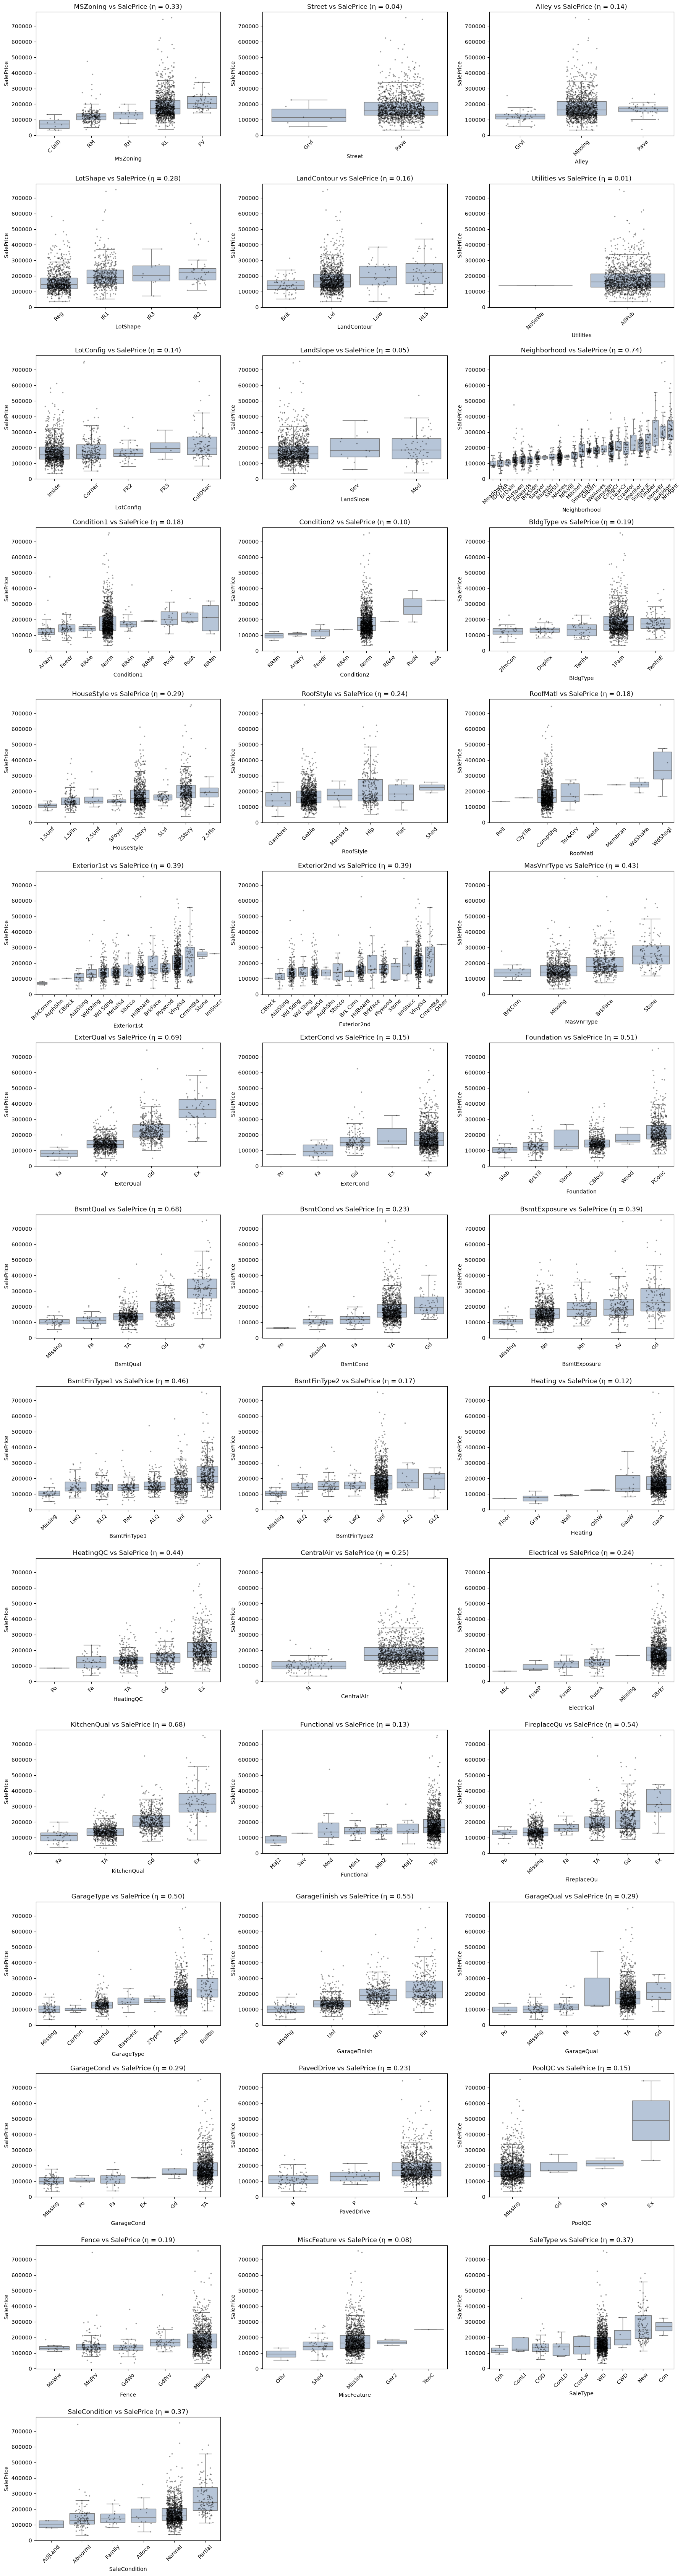

In [9]:
def correlation_ratio(categories, values):
    """Razón de correlación η entre una variable categórica y una numérica."""
    grand_mean = values.mean()
    groups = values.groupby(categories).agg(["mean", "count"])
    ss_between = (groups["count"] * (groups["mean"] - grand_mean) ** 2).sum()
    ss_total = ((values - grand_mean) ** 2).sum()
    return np.sqrt(ss_between / ss_total)


categoricas = train.select_dtypes(exclude="number").columns.tolist()
train_cat = train[categoricas].fillna("Missing")

etas = pd.Series({col: correlation_ratio(train_cat[col], train[TARGET]) for col in categoricas})

n_cols = 3
n_rows = int(np.ceil(len(categoricas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, categoricas):
    order = train[TARGET].groupby(train_cat[col]).median().sort_values().index
    sns.boxplot(x=train_cat[col], y=train[TARGET], order=order, showfliers=False, color="lightsteelblue", ax=ax)
    sns.stripplot(x=train_cat[col], y=train[TARGET], order=order, jitter=0.25, size=2.5, alpha=0.4, color="black", ax=ax)
    ax.set_title(f"{col} vs {TARGET} (η = {etas[col]:.2f})")
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(categoricas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 9. Selección de features

Selección de las `TOP_N` variables con mayor relación con `SalePrice` en cada grupo:

- **Continuas y discretas:** valor absoluto de la correlación de Pearson (|r|), para considerar por igual relaciones positivas y negativas.
- **Categóricas:** razón de correlación η.

La unión de los tres grupos conforma `modelo_features`, que se guarda junto con la variable objetivo y las features por tipo en `pipeline_config.yaml`, en la raíz del proyecto, para usarse en la construcción del modelo.

In [10]:
TOP_N = 10
CONFIG_FILE = PROJECT_ROOT / "pipeline_config.yaml"

top_continuas = correlations[continuas].abs().nlargest(TOP_N).index.tolist()
top_discretas = correlations[discretas].abs().nlargest(TOP_N).index.tolist()
top_categoricas = etas.nlargest(TOP_N).index.tolist()

modelo_features = top_continuas + top_discretas + top_categoricas

config = {
    "TARGET": TARGET,
    "MODEL_FEATURES": modelo_features,
    "CONTINUOUS_FEATURES": top_continuas,
    "DISCRETE_FEATURES": top_discretas,
    "CATEGORICAL_FEATURES": top_categoricas,
}
with open(CONFIG_FILE, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

print(f"Continuas:   {top_continuas}")
print(f"Discretas:   {top_discretas}")
print(f"Categóricas: {top_categoricas}")
print(f"\n{len(modelo_features)} features guardadas en {CONFIG_FILE.name}")

Continuas:   ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage']
Discretas:   ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'HalfBath', 'BsmtFullBath', 'BedroomAbvGr', 'KitchenAbvGr', 'PoolArea']
Categóricas: ['Neighborhood', 'ExterQual', 'BsmtQual', 'KitchenQual', 'GarageFinish', 'FireplaceQu', 'Foundation', 'GarageType', 'BsmtFinType1', 'HeatingQC']

30 features guardadas en pipeline_config.yaml
